Se explora la estrctura de los datos de una manera sencilla en notebook

In [3]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [4]:
import gc
import pandas as pd

archivos = [

    "../data/raw/datos_abiertos_2026_04.csv",
    "../data/raw/datos_abiertos_2026_05.csv",
    "../data/raw/datos_abiertos_2026_06.csv",
    "../data/raw/datos_abiertos_2026_07.csv",
    "../data/raw/datos_abiertos_2026_08.csv",
    "../data/raw/datos_abiertos_2026_09.csv",
]

dfs = []
for f in archivos:
    try:
        temp = pd.read_csv(f, encoding="utf-8")
    except UnicodeDecodeError:
        temp = pd.read_csv(f, encoding="latin-1")

    # Unificar nombres de columnas para evitar columnas duplicadas
    temp.columns = (
        temp.columns.str.replace("Año", "Anio")
        .str.replace("AÃ±o", "Anio")
        .str.strip()
    )

    # Reducir huella de memoria por tipos
    if "Genero" in temp.columns:
        temp["Genero"] = temp["Genero"].astype("category")

    dfs.append(temp)

# Concatenar y liberar la lista intermedia
df = pd.concat(dfs, ignore_index=True)
del dfs
gc.collect()

# Convertir fecha especificando formato para acelerar y ahorrar memoria
df["Inicio_del_viaje"] = pd.to_datetime(
    df["Inicio_del_viaje"], format="%Y-%m-%d %H:%M:%S", errors="coerce"
)

# Ordenar in-place para no duplicar el DataFrame de 4.5M de filas
df.sort_values(by="Inicio_del_viaje", inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"Dimensiones finales: {df.shape}")
print(f"Uso de memoria: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df.head()

Dimensiones finales: (2294886, 8)
Uso de memoria: 166.61 MB


,Viaje_Id,Usuario_Id,Genero,Anio_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,43570783,2765763,M,2002.0,2026-04-01 00:00:26,2026-04-01 00:18:17,358,158
1,43570784,1703556,M,1996.0,2026-04-01 00:00:44,2026-04-01 00:00:47,200,200
2,43570786,4037663,M,1995.0,2026-04-01 00:01:11,2026-04-01 00:03:46,287,95
3,43570787,1703556,M,1996.0,2026-04-01 00:01:14,2026-04-01 00:07:13,200,63
4,43570791,4636756,M,1986.0,2026-04-01 00:02:03,2026-04-01 00:12:24,193,155


In [5]:
# Guarda el dataset limpio y ordenado
df.to_parquet("../data/interim/viajes_2026_abr_sep.parquet", index=False)

In [6]:
df1 = pd.read_csv('../data/raw/nomenclatura_2026_09.csv')

In [7]:
# 1. Rango temporal cubierto
print("Fecha mínima:", df["Inicio_del_viaje"].min())
print("Fecha máxima:", df["Inicio_del_viaje"].max())

# 2. Conteo de nulos por columna
print("\nValores nulos:")
print(df.isna().sum())

# 3. Tipos y memoria final
print("\nInformación del DataFrame:")
df.info()

Fecha mínima: 2026-04-01 00:00:26
Fecha máxima: 2026-09-30 23:59:48

Valores nulos:
Viaje_Id                  0
Usuario_Id                0
Genero                14468
Anio_de_nacimiento      161
Inicio_del_viaje          0
Fin_del_viaje             0
Origen_Id                 0
Destino_Id                0
dtype: int64

Información del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 2294886 entries, 0 to 2294885
Data columns (total 8 columns):
 #   Column              Dtype         
---  ------              -----         
 0   Viaje_Id            int64         
 1   Usuario_Id          int64         
 2   Genero              category      
 3   Anio_de_nacimiento  float64       
 4   Inicio_del_viaje    datetime64[us]
 5   Fin_del_viaje       str           
 6   Origen_Id           int64         
 7   Destino_Id          int64         
dtypes: category(1), datetime64[us](1), float64(1), int64(4), str(1)
memory usage: 166.6 MB


In [8]:
# 1. Duplicados exactos en todas las columnas
duplicados_completos = df.duplicated().sum()
print(f"Filas 100% duplicadas: {duplicados_completos:,}")

# 2. Duplicados por clave única del viaje (Viaje_Id)
duplicados_viaje = df.duplicated(subset=["Viaje_Id"]).sum()
print(f"Viaje_Id repetidos: {duplicados_viaje:,}")

# 3. Comportamiento de Usuario_Id (es normal que se repitan si usan el servicio varias veces)
usuarios_unicos = df["Usuario_Id"].nunique()
print(f"Usuarios únicos: {usuarios_unicos:,}")
print(f"Promedio de viajes por usuario: {len(df) / usuarios_unicos:.2f}")

# 4. Limpieza (si existen Viaje_Id duplicados, conservar el primer registro)
if duplicados_viaje > 0:
    df.drop_duplicates(subset=["Viaje_Id"], keep="first", inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f"\nDataFrame tras eliminar duplicados: {df.shape}")
else:
    print("\nNo se encontraron duplicados en Viaje_Id. El dataset está íntegro.")

Filas 100% duplicadas: 758
Viaje_Id repetidos: 758
Usuarios únicos: 26,115
Promedio de viajes por usuario: 87.88

DataFrame tras eliminar duplicados: (2294128, 8)


In [9]:
# Convertir Fin_del_viaje si aún no está en datetime
df["Fin_del_viaje"] = pd.to_datetime(df["Fin_del_viaje"], errors="coerce")

# Calcular duración en minutos
df["duracion_minutos"] = (df["Fin_del_viaje"] - df["Inicio_del_viaje"]).dt.total_seconds() / 60.0

# 1. Chequeo de inconsistencias temporales
viajes_negativos = (df["duracion_minutos"] < 0).sum()
viajes_menores_1min = (df["duracion_minutos"] < 1).sum()
viajes_mayores_24h = (df["duracion_minutos"] > 1440).sum()

print(f"Viajes con fin anterior al inicio: {viajes_negativos:,}")
print(f"Viajes de menos de 1 min (posibles errores/candados trabados): {viajes_menores_1min:,}")
print(f"Viajes de más de 24 horas (bicicletas no regresadas): {viajes_mayores_24h:,}")

# Percentiles de duración típica
print("\nDistribución de duración (minutos):")
print(df["duracion_minutos"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

Viajes con fin anterior al inicio: 0
Viajes de menos de 1 min (posibles errores/candados trabados): 91,416
Viajes de más de 24 horas (bicicletas no regresadas): 9

Distribución de duración (minutos):
count    2.294128e+06
mean     1.077446e+01
std      1.058758e+01
min      0.000000e+00
5%       1.650000e+00
25%      5.450000e+00
50%      9.100000e+00
75%      1.435000e+01
95%      2.453333e+01
99%      3.408333e+01
max      4.543017e+03
Name: duracion_minutos, dtype: float64


In [10]:
# Calcular edad estimada tomando como referencia el año 2026
df["edad_aprox"] = 2026 - df["Anio_de_nacimiento"]

print("Distribución de edades:")
print(df["edad_aprox"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))

# Viajes con edades poco verosímiles (< 12 años o > 95 años)
edades_invalidas = ((df["edad_aprox"] < 12) | (df["edad_aprox"] > 95)).sum()
print(f"\nRegistros con edad fuera de rango razonable: {edades_invalidas:,}")

# Proporción por género
print("\nDistribución por Género:")
print(df["Genero"].value_counts(dropna=False, normalize=True) * 100)

Distribución de edades:
count    2.293967e+06
mean     3.535097e+01
std      1.722942e+01
min      1.600000e+01
1%       1.900000e+01
5%       2.200000e+01
50%      3.200000e+01
95%      5.700000e+01
99%      6.700000e+01
max      1.827000e+03
Name: edad_aprox, dtype: float64

Registros con edad fuera de rango razonable: 125

Distribución por Género:
Genero
M      72.221341
F      27.148006
NaN     0.630654
Name: proportion, dtype: float64


In [11]:
# Variables temporales derivadas
df["hora_inicio"] = df["Inicio_del_viaje"].dt.hour
df["dia_semana"] = df["Inicio_del_viaje"].dt.day_name()
df["es_fin_de_semana"] = df["Inicio_del_viaje"].dt.weekday >= 5

# Horas de mayor congestión
print("Top 5 horas de mayor demanda:")
print(df["hora_inicio"].value_counts().head(5))

# Comparación entre semana vs. fin de semana
print("\nDemanda por día de la semana:")
print(df["dia_semana"].value_counts(sort=False))

Top 5 horas de mayor demanda:
hora_inicio
18    202092
8     171682
17    169177
19    157683
15    151808
Name: count, dtype: int64

Demanda por día de la semana:
dia_semana
Wednesday    373991
Thursday     352053
Friday       344254
Saturday     263974
Sunday       237310
Monday       350020
Tuesday      372526
Name: count, dtype: int64


In [12]:
# 1. Viajes circulares (Origen == Destino)
mismo_destino = (df["Origen_Id"] == df["Destino_Id"]).sum()
print(f"Viajes que inician y terminan en la misma estación: {mismo_destino:,} ({mismo_destino / len(df) * 100:.2f}%)")

# 2. Rutas más frecuentes
top_rutas = (
    df.groupby(["Origen_Id", "Destino_Id"])
    .size()
    .reset_index(name="total_viajes")
    .sort_values(by="total_viajes", ascending=False)
    .head(10)
)
print("\nTop 10 trayectos más transitados:")
print(top_rutas)

# 3. Balance neto por estación (Salidas - Llegadas)
salidas = df["Origen_Id"].value_counts().rename("salidas")
llegadas = df["Destino_Id"].value_counts().rename("llegadas")

balance = pd.concat([salidas, llegadas], axis=1).fillna(0)
balance["balance_neto"] = balance["llegadas"] - balance["salidas"]

print("\nEstaciones con mayor acumulación de bicicletas (más llegadas que salidas):")
print(balance.sort_values(by="balance_neto", ascending=False).head(5))

print("\nEstaciones con mayor déficit de bicicletas (más salidas que llegadas):")
print(balance.sort_values(by="balance_neto", ascending=True).head(5))

Viajes que inician y terminan en la misma estación: 165,576 (7.22%)

Top 10 trayectos más transitados:
       Origen_Id  Destino_Id  total_viajes
13956         51          51          4970
13568         50          50          3243
2154          11          11          2484
42411        194          51          2467
62903        288         291          2402
59150        271         271          2259
15048         54          54          2149
42513        194         194          2081
18429         65          51          1986
9191          36          36          1894

Estaciones con mayor acumulación de bicicletas (más llegadas que salidas):
     salidas  llegadas  balance_neto
51     56191     62344          6153
341     6489     10814          4325
35     30499     34523          4024
56     14354     17992          3638
384     6647     10146          3499

Estaciones con mayor déficit de bicicletas (más salidas que llegadas):
     salidas  llegadas  balance_neto
194    25202     

In [16]:
# ---------------------------------------------------------
# 2) Tamaño real obtenido del dataset
# ---------------------------------------------------------

# 1. Rango temporal y conteo de meses cubiertos
fecha_min = df["Inicio_del_viaje"].min()
fecha_max = df["Inicio_del_viaje"].max()

# Periodos únicos (Año-Mes) ordenados con sorted()
meses_unicos = sorted(df["Inicio_del_viaje"].dt.to_period("M").unique())
n_meses = len(meses_unicos)
lista_meses = ", ".join([str(m) for m in meses_unicos])

# 2. Número total de viajes (filas tras eliminar duplicados)
n_viajes = len(df)

# 3. Número de estaciones en la red (unión de Origen y Destino)
estaciones_origen = set(df["Origen_Id"].dropna().astype(int).unique())
estaciones_destino = set(df["Destino_Id"].dropna().astype(int).unique())
todas_estaciones = estaciones_origen.union(estaciones_destino)
total_estaciones = len(todas_estaciones)

# Resumen en consola
print("=" * 60)
print("REPORTE: TAMAÑO REAL OBTENIDO")
print("=" * 60)
print(f"• Meses cubiertos:      {n_meses} meses ({lista_meses})")
print(f"• Rango de fechas:      Del {fecha_min.strftime('%Y-%m-%d %H:%M:%S')} al {fecha_max.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"• Número de viajes:     {n_viajes:,} registros válidos")
print(f"• Estaciones activas:   {total_estaciones:,} estaciones únicas en operación")
print(f"  - Como origen:        {len(estaciones_origen):,}")
print(f"  - Como destino:       {len(estaciones_destino):,}")
print("=" * 60)

REPORTE: TAMAÑO REAL OBTENIDO
• Meses cubiertos:      6 meses (2026-04, 2026-05, 2026-06, 2026-07, 2026-08, 2026-09)
• Rango de fechas:      Del 2026-04-01 00:00:26 al 2026-09-30 23:59:48
• Número de viajes:     2,294,128 registros válidos
• Estaciones activas:   471 estaciones únicas en operación
  - Como origen:        471
  - Como destino:       471


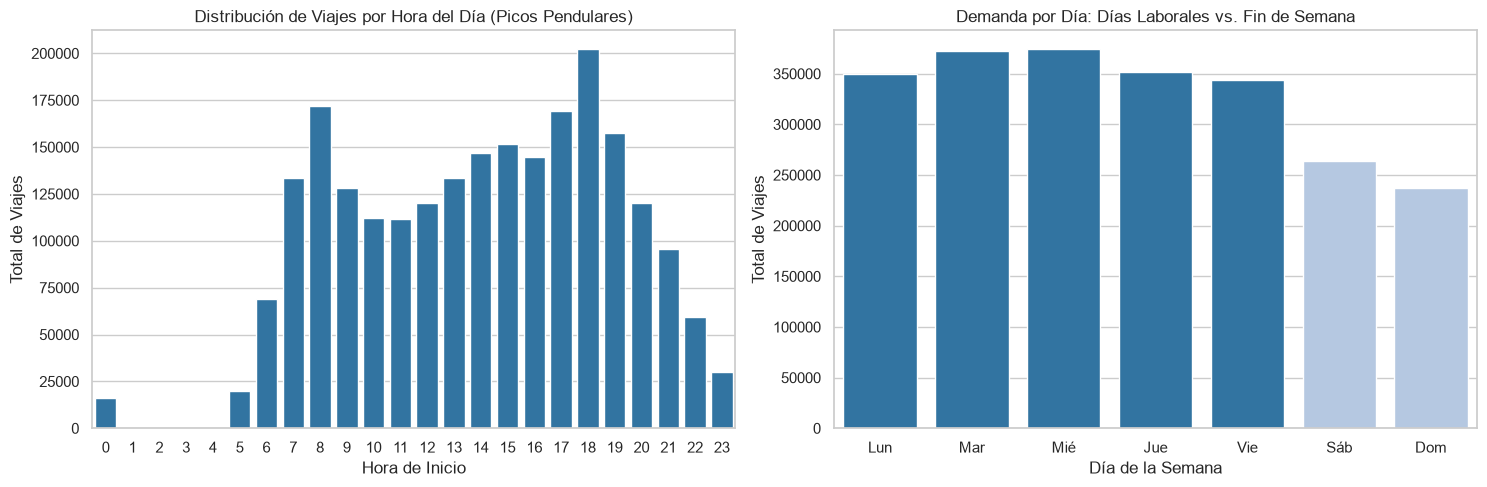

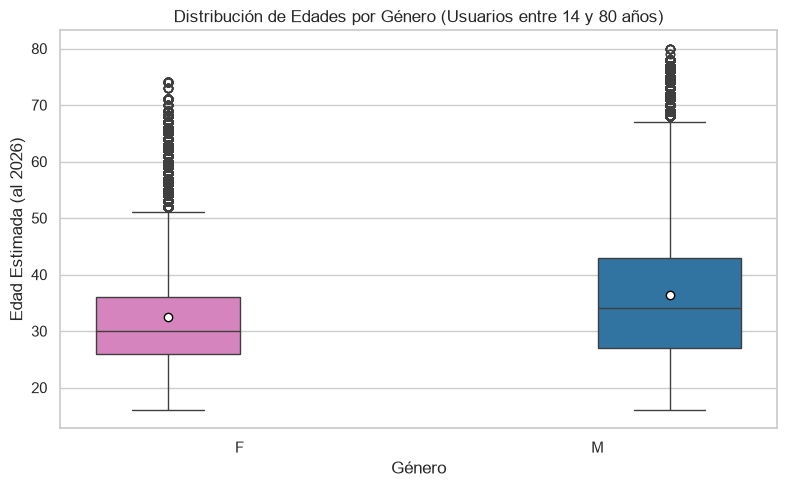

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_36064\1144280877.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


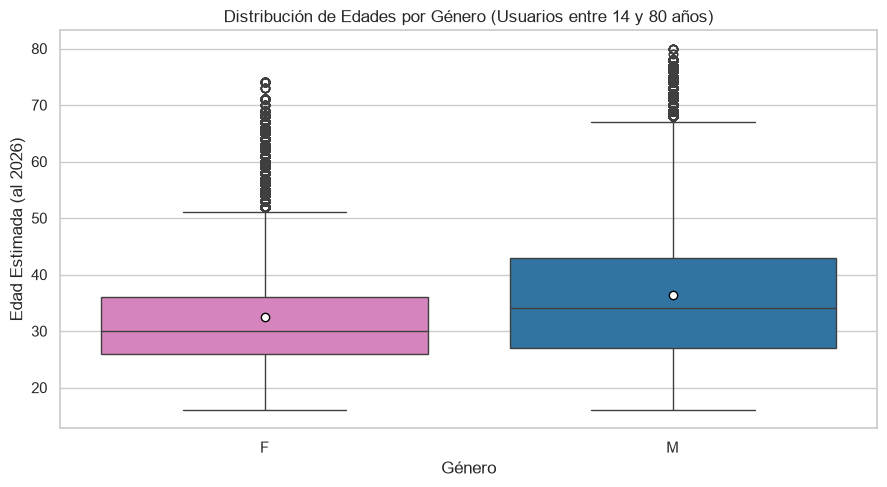

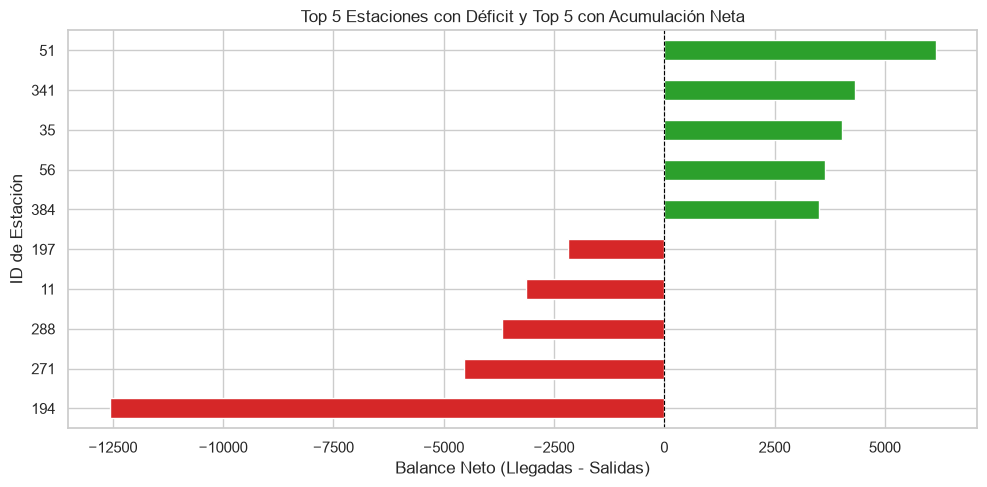

In [18]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------------
# 1. Perfil temporal de demanda: Horas del día y Días de la semana
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Demanda horaria
sns.countplot(
    data=df,
    x="hora_inicio",
    color="#1f77b4",
    ax=axes[0]
)
axes[0].set_title("Distribución de Viajes por Hora del Día (Picos Pendulares)")
axes[0].set_xlabel("Hora de Inicio")
axes[0].set_ylabel("Total de Viajes")

# Demanda por día de la semana
dias_orden = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dias_es = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
df_dias = df["dia_semana"].value_counts().reindex(dias_orden).reset_index()
df_dias.columns = ["dia_semana", "total_viajes"]
df_dias["dia_label"] = dias_es

sns.barplot(
    data=df_dias,
    x="dia_label",
    y="total_viajes",
    hue="dia_label",
    palette=["#1f77b4" if i < 5 else "#aec7e8" for i in range(7)],
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Demanda por Día: Días Laborales vs. Fin de Semana")
axes[1].set_xlabel("Día de la Semana")
axes[1].set_ylabel("Total de Viajes")

plt.savefig(output_dir / "01_demanda_temporal_horas_dias.png", dpi=300, bbox_inches="tight")
plt.show()

# -------------------------------------------------------------------------
# 2. Demografía: Distribución de Edad por Género
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
df_edad_valida = df[(df["edad_aprox"] >= 14) & (df["edad_aprox"] <= 80)].copy()

sns.boxplot(
    data=df_edad_valida,
    x="Genero",
    y="edad_aprox",
    hue="Genero",
    palette={"M": "#1f77b4", "F": "#e377c2"},
    legend=False,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"},
    ax=ax
)
ax.set_title("Distribución de Edades por Género (Usuarios entre 14 y 80 años)")
ax.set_xlabel("Género")
ax.set_ylabel("Edad Estimada (al 2026)")

plt.savefig(output_dir / "03_demografia_edad_genero.png", dpi=300, bbox_inches="tight")
plt.show()
# -------------------------------------------------------------------------
# 3. Demografía: Distribución de Edad por Género
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

df_edad_valida = df[(df["edad_aprox"] >= 14) & (df["edad_aprox"] <= 80)].copy()

sns.boxplot(
    data=df_edad_valida,
    x="Genero",
    y="edad_aprox",
    palette={"M": "#1f77b4", "F": "#e377c2"},
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
    },
    ax=ax,
)
ax.set_title("Distribución de Edades por Género (Usuarios entre 14 y 80 años)")
ax.set_xlabel("Género")
ax.set_ylabel("Edad Estimada (al 2026)")

plt.savefig(
    output_dir / "03_demografia_edad_genero.png", dpi=300, bbox_inches="tight"
)
plt.show()

# -------------------------------------------------------------------------
# 4. Desbalance Neto de Estaciones (Top Críticas para Logística)
# -------------------------------------------------------------------------
salidas = df["Origen_Id"].value_counts().rename("salidas")
llegadas = df["Destino_Id"].value_counts().rename("llegadas")
balance = pd.concat([salidas, llegadas], axis=1).fillna(0)
balance["balance_neto"] = balance["llegadas"] - balance["salidas"]

top_acumulan = balance.sort_values(by="balance_neto", ascending=False).head(5)
top_deficit = balance.sort_values(by="balance_neto", ascending=True).head(5)
criticas = pd.concat([top_acumulan, top_deficit]).sort_values(by="balance_neto")

fig, ax = plt.subplots(figsize=(10, 5))
colores = [
    "#d62728" if x < 0 else "#2ca02c" for x in criticas["balance_neto"]
]

criticas["balance_neto"].plot(kind="barh", color=colores, ax=ax)
ax.set_title("Top 5 Estaciones con Déficit y Top 5 con Acumulación Neta")
ax.set_xlabel("Balance Neto (Llegadas - Salidas)")
ax.set_ylabel("ID de Estación")
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")

plt.savefig(
    output_dir / "04_desbalance_estaciones_criticas.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [17]:
df1.head()

,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


In [19]:
# Información general y tipos
print("=== Estructura del dataset de estaciones ===")
df1.info()

# Conteo de valores nulos
print("\n=== Nulos por columna ===")
print(df1.isna().sum())

# Integridad de identificadores
print(f"\nIDs duplicados: {df1['id'].duplicated().sum()}")
print(f"Total estaciones en catálogo maestro: {df1['id'].nunique()}")

=== Estructura del dataset de estaciones ===
<class 'pandas.DataFrame'>
RangeIndex: 484 entries, 0 to 483
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          484 non-null    int64  
 1   name        484 non-null    str    
 2   latitude    484 non-null    float64
 3   longitude   484 non-null    float64
 4   dpcapacity  484 non-null    int64  
dtypes: float64(2), int64(2), str(1)
memory usage: 38.9 KB

=== Nulos por columna ===
id            0
name          0
latitude      0
longitude     0
dpcapacity    0
dtype: int64

IDs duplicados: 0
Total estaciones en catálogo maestro: 484


In [20]:
# Estadísticas descriptivas de la capacidad
print("=== Resumen de Capacidad (dpcapacity) ===")
print(df1["dpcapacity"].describe())

# Estaciones con menor y mayor capacidad
estacion_max = df1.loc[df1["dpcapacity"].idxmax()]
estacion_min = df1.loc[df1["dpcapacity"].idxmin()]

print(
    f"\nMayor capacidad ({estacion_max['dpcapacity']} candados): {estacion_max['name']}"
)
print(
    f"Menor capacidad ({estacion_min['dpcapacity']} candados): {estacion_min['name']}"
)

=== Resumen de Capacidad (dpcapacity) ===
count    484.000000
mean      16.882231
std        4.126942
min        0.000000
25%       15.000000
50%       15.000000
75%       19.000000
max       39.000000
Name: dpcapacity, dtype: float64

Mayor capacidad (39 candados): (GDL-049) Lopez Cotilla / Penitenciaría
Menor capacidad (0 candados): ex-(ZPN-009) C. Del Corral / C. Nicolás Bravo


In [21]:
print("=== Coordenadas geográficas ===")
print(df1[["latitude", "longitude"]].describe())

# Detección de posibles coordenadas fuera del área de servicio (GDL/Zapopan)
fuera_rango = df1[
    (df1["latitude"] < 20.5)
    | (df1["latitude"] > 20.8)
    | (df1["longitude"] < -103.5)
    | (df1["longitude"] > -103.2)
]
print(f"\nEstaciones fuera del rango geográfico esperado: {len(fuera_rango)}")

=== Coordenadas geográficas ===
         latitude   longitude
count  484.000000  484.000000
mean    20.678520 -103.361871
std      0.022032    0.031626
min     20.636130 -103.433215
25%     20.665077 -103.384164
50%     20.674390 -103.362443
75%     20.688609 -103.339320
max     20.739523 -103.297112

Estaciones fuera del rango geográfico esperado: 0


In [22]:
# Obtener IDs únicos del dataset de viajes (Origen y Destino)
estaciones_viajes = set(df["Origen_Id"].dropna().astype(int).unique()).union(
    set(df["Destino_Id"].dropna().astype(int).unique())
)
estaciones_catalogo = set(df1["id"].unique())

no_en_catalogo = estaciones_viajes - estaciones_catalogo
sin_viajes = estaciones_catalogo - estaciones_viajes

print(
    f"Estaciones con viajes que NO están en df1: {len(no_en_catalogo)}"
)
if no_en_catalogo:
    print(f"IDs huérfanos: {no_en_catalogo}")

print(
    f"Estaciones en df1 sin ningún viaje registrado (inactivas): {len(sin_viajes)}"
)

Estaciones con viajes que NO están en df1: 2
IDs huérfanos: {405, 407}
Estaciones en df1 sin ningún viaje registrado (inactivas): 15
